# Idoven ECG Machine Learning Task
In this notebook, we will go through the assigned task of training a ML model for working with the ECG data provided. We will explain our work, the code, the results and the insights taken. Hope you fin this interesting!

## Approach

Given the time frame, I decided not to pursue a single idea but showing a few that could be interesting to work with. A huge inspiration has been taken from [this kaggle notebook](https://www.kaggle.com/code/jraska1/ptb-xl-ecg-1d-convolution-neural-network#X-and-Y:-1D-CNN-Classifier), and this [paper](https://ieeexplore.ieee.org/document/9190034) and its corresponding [code](https://github.com/helme/ecg_ptbxl_benchmarking/tree/master), specially on the data prep part, but please note **our approach would not take into account two decoders** (one for the ECG and the other for the metadata info) but just one for the ECG. The reason for that is just exploring this part further and have a better individual understanding of it. **Please note a full 2 encoder + concat approach would probably be better**. 


As the good model metrics is not a requirement by definition, the goal on this exercise has been more a *breath* one rather than a *depth* one. **This means the main goal is not to create a high metric top model but to propose and briefly test different ideas**. If we wanted to have a top tier model, on the previous [repo](https://github.com/helme/ecg_ptbxl_benchmarking/tree/master) we could always replicate their [models](https://github.com/helme/ecg_ptbxl_benchmarking/tree/master#leaderboard) and get a very high AUC/F1 metric scoring model. 

As no good results are expected, no seed/reproductibility steps will be taken. Please note the experiments will probably stop after a few epochs, just to show if it is worthy to keep looking.

Please, reach the end of this document for a summary on the references/TODOs/conclussion

## Notebook structure

The notebook will contain all the code to execute. Ideally, I would distribute it into different folders (e.g:`src\models\models.py` for the different model architectures), but as the purpose of this notebook is to show and explain, I will include everything in here. Please note, for reproductibility and mintenability purposes, the code should be on modules rather than on this notebook.

We will start with a brief EDA (basically, what I would consider the main points from [here](https://www.kaggle.com/code/khyeh0719/ptb-xl-dataset-wrangling)), including some data preparation (a slight modification of the one in [here](https://www.kaggle.com/code/jraska1/ptb-xl-ecg-1d-convolution-neural-network#X-and-Y:-1D-CNN-Classifier)) and then, an example of the training of each model:


### Ideas/models to test
- A Baseline classifier
- A mode complex, 1D-CNN based one
- VAE + Classifier
- Pre-trained VIT + fine tune at classifier level





## EDA/DataPrep

Essentially, we have three different data: on the one side, what I'll call metadata (`pbxl_database.csv`). **Please note, for the sake of reproductibility, you should include the data in the same path as it is now**. Let's first take a look at what this metadata contains:


In [1]:
import os
import pandas as pd
import ast

DATA_PATH = './data/physionet.org/files/ptb-xl/1.0.2/'

# will load ECP metadata
df_metadata = pd.read_csv(os.path.join(DATA_PATH, 'ptbxl_database.csv'))

df_metadata.head()

,ecg_id,patient_id,age,sex,height,weight,nurse,site,device,recording_date,...,SLI-LVH,QRS-CLBB,ST-ELEV-MI,ST-DEPR-MI,Q-ISC,Q-ISC-QPeak,Q-ISC-V2V3,Q-ISC-RPeak,STRAIN,MI-ALL
0,1,15709.0,56.0,1,NaN,63.0,2.0,0.0,CS-12 E,1984-11-09 09:17:34,...,False,False,False,False,False,False,False,False,False,False
1,2,13243.0,19.0,0,NaN,70.0,2.0,0.0,CS-12 E,1984-11-14 12:55:37,...,True,False,False,False,False,False,False,False,False,False
2,3,20372.0,37.0,1,NaN,69.0,2.0,0.0,CS-12 E,1984-11-15 12:49:10,...,False,False,False,False,False,False,False,False,False,False
3,4,17014.0,24.0,0,NaN,82.0,2.0,0.0,CS-12 E,1984-11-15 13:44:57,...,False,False,False,False,False,False,False,False,False,False
4,5,17448.0,19.0,1,NaN,70.0,2.0,0.0,CS-12 E,1984-11-17 10:43:15,...,False,False,False,False,False,False,False,False,False,False


As you can see, it contains plenty of info about each patient (some might appear twice!), some ECG statements (validation, second opinion, ...) and signal quality. Those seem indeed a nice source for filtering and cleaning data for a better training and perhaps should be taken more carefully in a deeper approach. A very important fact here is that we can see a single ECG might have more than one diagnostic

In [2]:
df_metadata.scp_codes = df_metadata.scp_codes.apply(lambda x: ast.literal_eval(x))
df_metadata.scp_codes[21796]

{'NDT': 100.0, 'PVC': 100.0, 'VCLVH': 0.0, 'STACH': 0.0}

As you can see, the scp codes is a dictionary per ECG, with the diagnose as a key and the confidence as a value (0 if unknown). This is also something to be taken into account, but first of all, the case is a multi-label classification problem.

#### Diagnostic statements

There is another kind of data: the statements that include some info about each diagnostic, but we will focus on the class/subclass one. In this exercise, we are going to predict at class level (up to 5 labels), but we could always work at subclass if needed.

In [3]:
# will load the statements data
df_statements = pd.read_csv(os.path.join(DATA_PATH, 'scp_statements.csv'), index_col=0)
# will only check valid diagnostics
df_statements = df_statements[~df_statements.diagnostic.isna()]
df_statements

,description,diagnostic,form,rhythm,diagnostic_class,diagnostic_subclass,Statement Category,SCP-ECG Statement Description,AHA code,aECG REFID,CDISC Code,DICOM Code
NDT,non-diagnostic T abnormalities,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,non-diagnostic T abnormalities,NaN,NaN,NaN,NaN
NST_,non-specific ST changes,1.0,1.0,NaN,STTC,NST_,Basic roots for coding ST-T changes and abnorm...,non-specific ST changes,145.0,MDC_ECG_RHY_STHILOST,NaN,NaN
DIG,digitalis-effect,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,suggests digitalis-effect,205.0,NaN,NaN,NaN
LNGQT,long QT-interval,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,long QT-interval,148.0,NaN,NaN,NaN
NORM,normal ECG,1.0,NaN,NaN,NORM,NORM,Normal/abnormal,normal ECG,1.0,NaN,NaN,F-000B7
IMI,inferior myocardial infarction,1.0,NaN,NaN,MI,IMI,Myocardial Infarction,inferior myocardial infarction,161.0,NaN,NaN,NaN
ASMI,anteroseptal myocardial infarction,1.0,NaN,NaN,MI,AMI,Myocardial Infarction,anteroseptal myocardial infarction,165.0,NaN,NaN,NaN
LVH,left ventricular hypertrophy,1.0,NaN,NaN,HYP,LVH,Ventricular Hypertrophy,left ventricular hypertrophy,142.0,NaN,C71076,NaN
LAFB,left anterior fascicular block,1.0,NaN,NaN,CD,LAFB/LPFB,Intraventricular and intra-atrial Conduction d...,left anterior fascicular block,101.0,MDC_ECG_BEAT_BLK_ANT_L_HEMI,C62267,D3-33140
ISC_,non-specific ischemic,1.0,NaN,NaN,STTC,ISC_,Basic roots for coding ST-T changes and abnorm...,ischemic ST-T changes,226.0,NaN,NaN,NaN


#### Diagnostic aggregation

We will, then, aggregate all diagnoses. As a difference from the reference, I've added a conf threshold value so that we would ignore the diagnoses that don't have a lot of confidence. Perhaps this is something to dig deeper.

In [4]:
CONFIDENCE_THRESHOLD = 20
def diagnostic_class(scp, verbose=False):
    """
    Will just aggregate the labels
    """
    res = set()
    for k, v in scp.items():
        if v == 0 or v  > CONFIDENCE_THRESHOLD:
            if k in df_statements.index:

                res.add(df_statements.loc[k].diagnostic_class)
        elif verbose:
            print(scp.items())
    return list(res)


df_metadata['scp_classes'] = df_metadata.scp_codes.apply(diagnostic_class)
df_metadata.scp_classes.value_counts()


scp_classes
[NORM]                 9042
[STTC]                 2576
[CD]                   2016
[MI]                   1929
[]                     1182
[MI, CD]               1015
[STTC, HYP]             794
[STTC, CD]              517
[MI, STTC]              459
[HYP]                   458
[NORM, CD]              400
[MI, STTC, HYP]         304
[HYP, CD]               241
[MI, STTC, CD]          182
[MI, HYP]               130
[CD, STTC, HYP]         119
[HYP, STTC, CD]          99
[MI, CD, STTC, HYP]      91
[HYP, MI, CD]            87
[CD, HYP]                56
[HYP, MI, STTC, CD]      51
[NORM, STTC]             27
[MI, CD, HYP]            16
[NORM, STTC, CD]          5
[HYP, NORM, CD]           2
[NORM, HYP]               2
[HYP, NORM, CD, MI]       1
Name: count, dtype: int64

You can see here the different labels for different diagnoses. It is quite interesting that we have 1182 with no diagnostic class. Perhaps those ones could be removed for a cleaner training

### Diagnose Classes


It is quite interesting to take a look at what do each class mean. extracted from [Here](https://www.kaggle.com/code/khyeh0719/ptb-xl-dataset-wrangling), we have some definitions of the labels:

- NORM: Normal ECG
- MI: Myocardial Infarction, a myocardial infarction (MI), commonly known as a heart attack, occurs when blood flow decreases or stops to a part of the heart, causing damage to the heart muscle Reference
- STTC: ST/T Change, ST and T wave changes may represent cardiac pathology or be a normal variant. Interpretation of the findings, therefore, depends on the clinical context and presence of similar findings on prior electrocardiograms.Reference
- CD: Conduction Disturbance. Your heart rhythm is the way your heart beats. Conduction is how electrical impulses travel through your heart, which causes it to beat. Some conduction disorders can cause arrhythmias, or irregular heartbeats. Reference
- HYP: Hypertrophy, Hypertrophic cardiomyopathy (HCM) is a disease in which the heart muscle becomes abnormally thick (hypertrophied). The thickened heart muscle can make it harder for the heart to pump blood. Reference




#### ECG Data

This is, indeed, the very focus of my exercise. We are going to load the signals one by one

In [5]:
import wfdb
import numpy as np
from random import random
NUM_EXAMPLES = 10
RANDOM_THRESHOLD = 0.999
def load_raw_data(df, path):
    data = []
    num_cases = 0
    for f in df.filename_lr:
        # if os.path.exists(os.path.join(path, f + '.hea')):
        info = wfdb.rdsamp(os.path.join(path, f))
        if num_cases < NUM_EXAMPLES and random() > RANDOM_THRESHOLD:
            print(info[1])
            num_cases +=1
        data.append(info)
        # else:
        #     print(os.path.join(path, f))
        
    data = np.array([signal for signal, meta in data])
    return data

ECG_data = load_raw_data(df_metadata, DATA_PATH)

ECG_data.shape


{'fs': 100, 'sig_len': 1000, 'n_sig': 12, 'base_date': None, 'base_time': None, 'units': ['mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV'], 'sig_name': ['I', 'II', 'III', 'AVR', 'AVL', 'AVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6'], 'comments': []}
{'fs': 100, 'sig_len': 1000, 'n_sig': 12, 'base_date': None, 'base_time': None, 'units': ['mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV'], 'sig_name': ['I', 'II', 'III', 'AVR', 'AVL', 'AVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6'], 'comments': []}
{'fs': 100, 'sig_len': 1000, 'n_sig': 12, 'base_date': None, 'base_time': None, 'units': ['mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV'], 'sig_name': ['I', 'II', 'III', 'AVR', 'AVL', 'AVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6'], 'comments': []}
{'fs': 100, 'sig_len': 1000, 'n_sig': 12, 'base_date': None, 'base_time': None, 'units': ['mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV'], 'sig_name': ['I', 'II', 'III', 'A

(21801, 1000, 12)

We have stored the ECG data on an np arary. Plese note the random part is just to randomly test the info that is attached to each file is actually non-informative. Further tests could be done for this, but I consider it non-necessary. Now, about the data. We have 21801 examples with 1000 points (the 10 secs and the 100 fs) and 12 signals. Let's take a look at some of them:

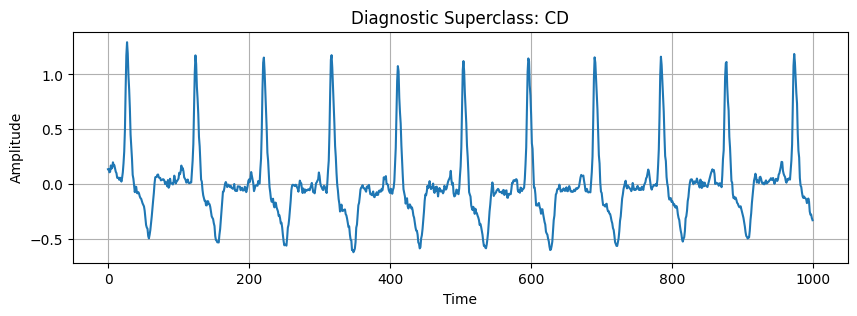

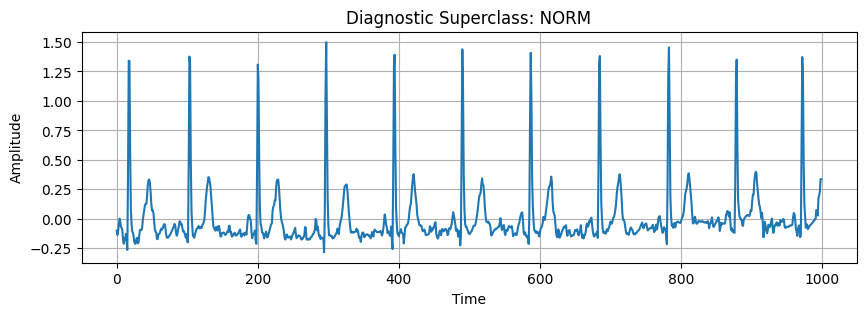

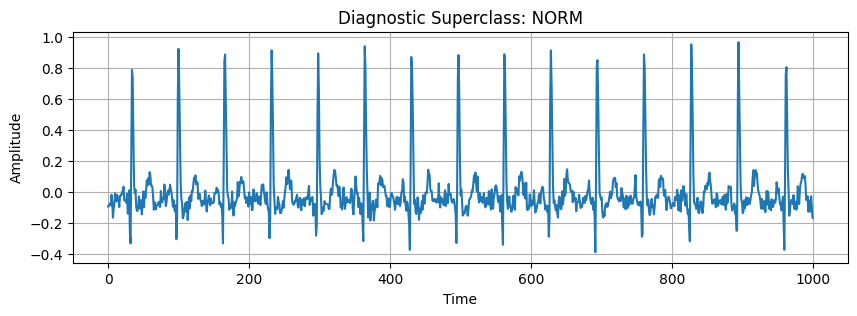

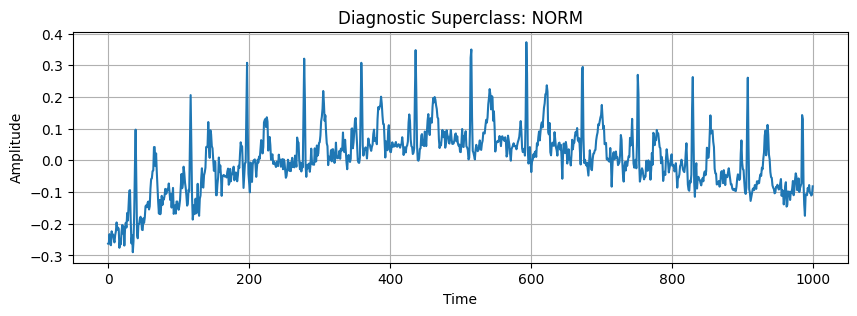

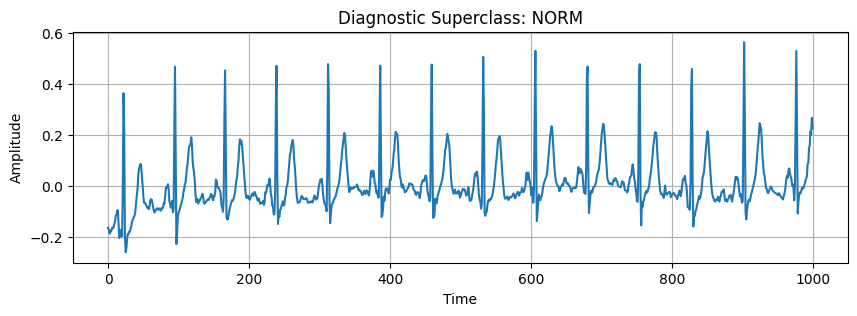

In [6]:
import matplotlib.pyplot as plt

def plot_ecg_examples(ECG_data, metadata, num_examples=5):
    # Randomly select some examples
    idx = np.random.choice(np.arange(len(ECG_data)), num_examples, replace=False)
    
    for i in idx:
        plt.figure(figsize=(10, 3))
        plt.plot(ECG_data[i].T[0]) # remove the subindex for a full plot on all channels
        plt.title(f"Diagnostic Superclass: {', '.join(metadata.iloc[i])}")
        plt.xlabel('Time')
        plt.ylabel('Amplitude')
        plt.grid(True)
        plt.show()

# To visualize 5 random examples from the training set:
plot_ecg_examples(ECG_data, df_metadata.scp_classes, num_examples=5)



Please note just the first channel is being plotted. For a deeper understanding, perhaps we should be seeing all 12. In my non expert eyes, I can see not a real motivation for diagnosing any of those, but probably, for a physician, it would be clear

#### Additional EDA and insights

One of the things that might be interesting for the model training is the age distribution. As one could expect, most issues do happen when the person is of older age:

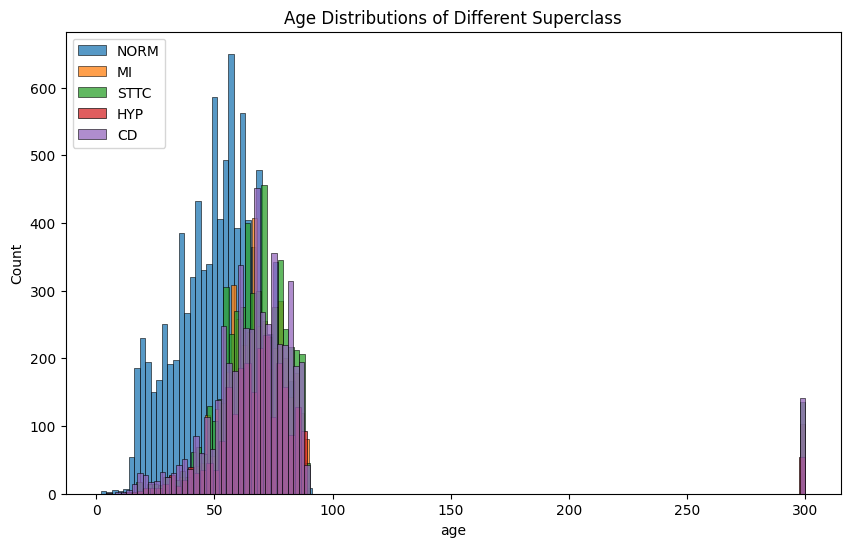

In [7]:
import seaborn as sns
all_superclass = pd.Series(np.concatenate(df_metadata.scp_classes.values))
superclass_cols = all_superclass.unique()
fig, ax = plt.subplots(figsize=(10,6))
plt.title('Age Distributions of Different Superclass')

for superclass in superclass_cols:
    sub = df_metadata.scp_classes.apply(lambda x: superclass in x)
    data = df_metadata[sub]['age']   
    sns.histplot(data, label=superclass)


plt.legend(loc='upper left')
plt.show()



It is also worthy of mentioning that depending on the device, there are different distributions on the diagnostics. I won't execute the whole code, but I'll paste a picture from [here](https://www.kaggle.com/code/khyeh0719/ptb-xl-dataset-wrangling). This one ![alternative text](./images/devices.png)


#### Further DataPrep

Let's now prepare our data for being used in our models. First, let's start with the targets, and let's encode them:

In [8]:
Z = pd.DataFrame(0, index=df_metadata.index, columns=['NORM', 'MI', 'STTC', 'CD', 'HYP'], dtype='int')
for i in Z.index:
    for k in df_metadata.loc[i].scp_classes:
        Z.loc[i, k] = 1

Z.to_numpy()

array([[1, 0, 0, 0, 0],
       [1, 0, 0, 0, 0],
       [1, 0, 0, 0, 0],
       ...,
       [0, 0, 1, 0, 0],
       [1, 0, 0, 0, 0],
       [1, 0, 0, 0, 0]])

As you can see, it is a multi-label dummy encoding. Now, let's work with the ECG data, the train/val/test dataset generation and so on. We will use the recommendations on the folding.

In [48]:
Y_train_raw, Z_train = ECG_data[df_metadata[df_metadata.strat_fold <= 8].index],  Z[df_metadata.strat_fold <= 8]
Y_valid_raw, Z_valid = ECG_data[df_metadata[df_metadata.strat_fold == 9].index],  Z[df_metadata.strat_fold == 9]
Y_test_raw,  Z_test  = ECG_data[df_metadata[df_metadata.strat_fold == 10].index], Z[df_metadata.strat_fold == 10]

Y_test_raw.shape



(2198, 1000, 12)

We will keep the df format on Z for now, for label understanding purposes mainly. Let's now scale the Y dataset (aka, the ECG data)

In [49]:
from sklearn.preprocessing import StandardScaler
Y_scaler = StandardScaler()
Y_scaler.fit(Y_train_raw.reshape(-1, Y_train_raw.shape[-1]))

Y_train = Y_scaler.transform(Y_train_raw.reshape(-1, Y_train_raw.shape[-1])).reshape(Y_train_raw.shape)
Y_valid = Y_scaler.transform(Y_valid_raw.reshape(-1, Y_valid_raw.shape[-1])).reshape(Y_valid_raw.shape)
Y_test  = Y_scaler.transform(Y_test_raw.reshape(-1, Y_test_raw.shape[-1])).reshape(Y_test_raw.shape)
Y_test

array([[[-8.90690898e-01, -5.81576012e-01,  2.91830244e-01, ...,
         -1.51035355e+00, -9.81588339e-01, -1.05567692e-01],
        [-7.04185059e-01, -4.96324241e-01,  1.90093998e-01, ...,
         -1.13162918e+00, -8.97408676e-01, -1.37667502e-01],
        [-3.87125133e-01, -3.56267761e-01,  2.85129011e-02, ...,
         -6.25546181e-01, -7.25389364e-01, -1.34100857e-01],
        ...,
        [ 1.44063209e+00,  1.78720533e+00,  3.75613035e-01, ...,
          1.48927750e+00,  1.32786243e+00,  8.00360296e-01],
        [ 1.57118618e+00,  1.95161946e+00,  3.99550975e-01, ...,
          1.67361236e+00,  1.48524180e+00,  9.39459475e-01],
        [ 2.11205311e+00,  2.20737477e+00,  1.36233632e-01, ...,
          1.73058860e+00,  1.63896118e+00,  1.07499201e+00]],

       [[ 1.14222275e+00,  1.20262176e+00,  7.63887816e-02, ...,
          1.38873120e+00,  1.02408364e+00,  1.02149232e+00],
        [ 1.44063209e+00,  1.89072533e+00,  4.71364796e-01, ...,
          1.76075248e+00,  1.46694187e

### Further info

We are not going to cover signal quality here. Please note this is worthy to check, but it could take long.

### Model training basics

As we are going to train more than one model, we will start by creating a basic structure for all of the common things. Please note the code will be explained inside the cells. Let's first start by creating a dataset and dataloader for each:

In [50]:
from torch.utils.data import DataLoader, Dataset

class ECGDataset(Dataset):
    def __init__(self, ecg_data, labels):
        self.ecg_data = ecg_data
        self.labels = labels
    
    def __len__(self):
        return len(self.ecg_data)
    
    def __getitem__(self, idx):
        return self.ecg_data[idx], self.labels[idx]


# Create dataset and dataloader
train_dataset = ECGDataset(Y_train, Z_train.to_numpy())
train_dataloader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_dataset = ECGDataset(Y_test, Z_test.to_numpy())
test_dataloader = DataLoader(test_dataset, batch_size=32, shuffle=True)
valid_dataset = ECGDataset(Y_valid, Z_valid.to_numpy())
valid_dataloader = DataLoader(valid_dataset, batch_size=32, shuffle=True)



train_dataset_raw = ECGDataset(Y_train_raw, Z_train.to_numpy())
train_dataloader_raw = DataLoader(train_dataset_raw, batch_size=32, shuffle=True)
test_dataset_raw = ECGDataset(Y_test_raw, Z_test.to_numpy())
test_dataloader_raw = DataLoader(test_dataset_raw, batch_size=32, shuffle=True)
valid_dataset_raw = ECGDataset(Y_valid_raw, Z_valid.to_numpy())
valid_dataloader_raw = DataLoader(valid_dataset_raw, batch_size=32, shuffle=True)

##### Metrics

We will be using F1 mostly, but we will also compute accuracy, precision, and recall. Please note we will skip AUC opposed to the leaderboard in [here](https://github.com/helme/ecg_ptbxl_benchmarking/tree/master) for an easier interpretability. **Please note the metrics should be standard for the use case in case we want to compare ourselves with a benchmark**. Please note I'll be using my Mac mps device, but this code should work on another machine with and without GPU

In [51]:
import torch
from torchmetrics.classification import MultilabelPrecision, MultilabelRecall, MultilabelF1Score, MultilabelAccuracy


# Move model and metrics to the device (GPU or CPU)
device = torch.device('mps') if torch.backends.mps.is_available() else torch.device("cuda" if torch.cuda.is_available() else "cpu")
# Define the number of labels (classes) for multi-label classification
num_labels = 5

# Initialize the metrics
f1_score = MultilabelF1Score(num_labels=num_labels, average="macro").to(device)
precision = MultilabelPrecision(num_labels=num_labels, average="macro").to(device)
recall = MultilabelRecall(num_labels=num_labels, average="macro").to(device)
accuracy = MultilabelAccuracy(num_labels=num_labels).to(device)

# These metrics will be updated per batch and then computed for the entire dataset.

#### Model definition

We will define our models as a class in order to have an easy instantiation of them later on. As we will be using pure pytorch, everything should be mostly compatible. We will then define a standard weights initialization, a training epoch, an evaluation and a model training loop. Please note the following code note:

- Apply sigmoid to get binary probabilities. In a model to be used with BCEWithLogits, the model output doesn't expect them while the loss function will skip the computation for the loss. This is why in this case, for comparing with the actual ground truth probs, we need them on sigmoid way

In [52]:
import torch
import torch.nn as nn
import torch.optim as optim

# Initialize weights
def init_weights(m):
    """
    Just a weight initialization on linear layers
    """
    if isinstance(m, nn.Linear):
        torch.nn.init.xavier_uniform_(m.weight)
        if m.bias is not None:
            m.bias.data.fill_(0.01)


def train_epoch(dataloader, device, optimizer, model, criterion):
    """
    In this function we will make use of the dataloader and use all model agents (optimizer, criterion)
    for computing and backpropagating the loss. Please note the "float()" is moslty used due to both
    numpy-torch conversions and sometimes, issues with my device (using a mac)
    """
    model.train()
    total_loss = 0
    for batch_idx, (ecg_batch, labels_batch) in enumerate(dataloader):
        # Move data to the appropriate device
        ecg_batch, labels_batch = ecg_batch.float().to(device), labels_batch.float().to(device)
        optimizer.zero_grad()
        # Forward pass
        outputs = model(ecg_batch)
        # Compute loss
        loss = criterion(outputs, labels_batch.float())
        # Backward pass and optimization
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    
    return total_loss / len(dataloader) 


def evaluate(dataloader, device, model, criterion, use_sigmoid=True, prediction_threshold=0.5):
    """
    Will evaluate the model on the selected metrics. Feel free to add more
    Please also note the sigmoid usage, as we will mostly optimize with BCEWithLogits for
    a more performant model training
    """
    model.eval()
    total_loss = 0
    with torch.no_grad():
        for batch_idx, (ecg_batch, labels_batch) in enumerate(dataloader):
            ecg_batch, labels_batch = ecg_batch.float().to(device), labels_batch.float().to(device)
            outputs = model(ecg_batch)
            if use_sigmoid:
                # Apply sigmoid to get binary probabilities. In a model to be used with BCEWithLogits, the model output doesn't expect them
                # while the loss function will skip the computation for the loss. This is why in this case, for comparing with the actual 
                # ground truth probs, we need them on sigmoid way
                predicted_probs = torch.sigmoid(outputs)
            else:
                predicted_probs = outputs
            loss = criterion(outputs, labels_batch.float()).item()

            # Convert probabilities to binary predictions 
            preds = (predicted_probs > prediction_threshold).float()
            # Update the metrics
            f1_score.update(preds, labels_batch)
            precision.update(preds, labels_batch)
            recall.update(preds, labels_batch)
            accuracy.update(preds, labels_batch)
            total_loss += loss
        # Compute and print metrics at the end of the epoch
        f1_value = f1_score.compute().item()
        precision_value = precision.compute().item()
        recall_value = recall.compute().item()
        accuracy_value = accuracy.compute().item()
        # Reset metrics for the next epoch
        f1_score.reset()
        precision.reset()
        recall.reset()
        accuracy.reset()
    return total_loss / len(dataloader) , f1_value, precision_value, recall_value, accuracy_value


def predict_classes(dataloader, device, model, use_sigmoid=True, pred_threshold=0.5):
    """
    Will perform a prediction. Please note it would be at label level. So, a sigmoid is applied, and it is compared to a threhold for the hard preds
    """
    model.eval()
    pred_list = []
    with torch.no_grad():
        for batch_idx, (ecg_batch, labels_batch) in enumerate(dataloader):
            ecg_batch, labels_batch = ecg_batch.float().to(device), labels_batch.float().to(device)
            outputs = model(ecg_batch)
            if use_sigmoid:
                # Apply sigmoid to get binary probabilities. In a model to be used with BCEWithLogits, the model output doesn't expect them
                # while the loss function will skip the computation for the loss. This is why in this case, for comparing with the actual 
                # ground truth probs, we need them on sigmoid way
                predicted_probs = torch.sigmoid(outputs)
            else:
                predicted_probs = outputs
            # Convert probabilities to binary predictions (threshold = 0.5)
            preds = (predicted_probs > pred_threshold).float()
            pred_list.append(preds)
    return torch.cat(pred_list, dim=0)

def train_model(model, num_epochs, device, optimizer, criterion, scheduler=None, train_dataloader=train_dataloader, valid_dataloader=valid_dataloader):
    """
    Will train the model: train for an epoch, compute metrics, update the scheduler if defined
    """
    model.apply(init_weights)
    for epoch in range(num_epochs):

        loss = train_epoch(train_dataloader, device=device, optimizer=optimizer, model=model, criterion=criterion)
        valid_loss, f1_value, precision_value, recall_value, accuracy_value = evaluate(valid_dataloader, device=device, model=model, criterion=criterion)
        if scheduler is not None:
            scheduler.step(metrics=valid_loss)  # Adjust learning rate after each epoch

        print(f'Epoch [{epoch+1}/{num_epochs}], Train Loss: {loss:.4f}, Valid Loss: {valid_loss:.4f}')
        print(f'F1 Score: {f1_value:.4f}, Precision: {precision_value:.4f}, Recall: {recall_value:.4f}, Accuracy: {accuracy_value:.4f}')
    

    return model




#### First model: A baseline linear model
In this case, we will define a very basic MLP for having a baseline. This one will flatten the input to a 2d matrix (batch size, channels * seq_len) and then, apply the linear layers to it

In [53]:
class ECGClassifier(nn.Module):
    def __init__(self, input_size=1000, num_channels=12, num_classes=5, hidden_size=128):
        super(ECGClassifier, self).__init__()
        
        # A basic feedforward network
        self.fc1 = nn.Linear(num_channels * input_size, hidden_size)
        self.dropout = nn.Dropout(p=0.5)
        self.fc2 = nn.Linear(hidden_size, num_classes)
        self.relu = nn.ReLU()  # Use ReLU to avoid vanishing gradients

    def forward(self, x):
        # Flatten input from [batch_size, channels, seq_len] to [batch_size, channels * seq_len]
        x = x.view(x.size(0), -1)  # Flatten the ECG data
        # Forward pass through the network
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        out = self.fc2(x)
        
        return out  # Return raw logits, no sigmoid

Now, let's train our model. As mentioned before, we will be using Binary Cross Entropy with Logits as the loss function. The reason for that is that BCE should work fine with a multi-label class problem and the logits without sigmoid would help on the model training

In [54]:
# Initialize the metrics (again)
f1_score = MultilabelF1Score(num_labels=num_labels, average="macro").to(device)
precision = MultilabelPrecision(num_labels=num_labels, average="macro").to(device)
recall = MultilabelRecall(num_labels=num_labels, average="macro").to(device)
accuracy = MultilabelAccuracy(num_labels=num_labels).to(device)
# Initialize model, optimizer, and loss function
model = ECGClassifier(input_size=1000, num_channels=12).to(device)
optimizer = optim.AdamW(model.parameters(), lr=0.01, weight_decay=1e-5)

criterion = nn.BCEWithLogitsLoss()
num_epochs = 10

trained_model = train_model(model, num_epochs, device, optimizer, criterion)

Epoch [1/10], Train Loss: 3.1238, Valid Loss: 2.3102
F1 Score: 0.2133, Precision: 0.2519, Recall: 0.1891, Accuracy: 0.6822
Epoch [2/10], Train Loss: 4.6787, Valid Loss: 4.2342
F1 Score: 0.1563, Precision: 0.2613, Recall: 0.1640, Accuracy: 0.7332
Epoch [3/10], Train Loss: 5.9166, Valid Loss: 6.5771
F1 Score: 0.1206, Precision: 0.3494, Recall: 0.0897, Accuracy: 0.7312
Epoch [4/10], Train Loss: 5.7971, Valid Loss: 3.3630
F1 Score: 0.2885, Precision: 0.2724, Recall: 0.3255, Accuracy: 0.6558
Epoch [5/10], Train Loss: 7.8033, Valid Loss: 8.9943
F1 Score: 0.1879, Precision: 0.3044, Recall: 0.2144, Accuracy: 0.7255
Epoch [6/10], Train Loss: 7.6009, Valid Loss: 4.3550
F1 Score: 0.2618, Precision: 0.2737, Recall: 0.2929, Accuracy: 0.6798
Epoch [7/10], Train Loss: 9.2524, Valid Loss: 4.7845
F1 Score: 0.2732, Precision: 0.3051, Recall: 0.3341, Accuracy: 0.6497
Epoch [8/10], Train Loss: 6.9963, Valid Loss: 3.8957
F1 Score: 0.2338, Precision: 0.2892, Recall: 0.2177, Accuracy: 0.7144
Epoch [9/10], Tr

Not very good it seems... It tended to overfit as losses show. It seems that it did underfit too. Let's check performances on train:

In [55]:
f1_score = MultilabelF1Score(num_labels=num_labels, average="macro").to(device)
precision = MultilabelPrecision(num_labels=num_labels, average="macro").to(device)
recall = MultilabelRecall(num_labels=num_labels, average="macro").to(device)
accuracy = MultilabelAccuracy(num_labels=num_labels).to(device)
evaluate(train_dataloader, device, trained_model, criterion=criterion, use_sigmoid=True, prediction_threshold=0.5)

(5.8981903649251395,
 0.2818223834037781,
 0.39472711086273193,
 0.2494964748620987,
 0.7376807928085327)

Training performance was also bad. **One possible solution could be working on data augmentation** so that it could work better on unseen data. However, it is not the goal I'm pursuing. I'll try different architectures instead to see if we can get any benefit from the architecture change. For example, what if we use Conv1D? Seems to be pretty neat according to [this](https://www.kaggle.com/code/jraska1/ptb-xl-ecg-1d-convolution-neural-network#X-and-Y:-1D-CNN-Classifier). In fact, we tried to replicate the architecture of the Y encoder in torch.

In [61]:
class ECGConvNet(nn.Module):
    def __init__(self, input_channels, filters=(32, 64, 128), kernel_size=(5, 3, 3), strides=(1, 1, 1)):
        super(ECGConvNet, self).__init__()
        f1, f2, f3 = filters
        k1, k2, k3 = kernel_size
        s1, s2, s3 = strides
        
        self.conv1 = nn.Conv1d(input_channels, f1, k1, stride=s1, padding='same')
        self.norm1 = nn.BatchNorm1d(f1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool1d(2)
        
        self.conv2 = nn.Conv1d(f1, f2, k2, stride=s2, padding='same')
        self.norm2 = nn.BatchNorm1d(f2)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool1d(2)
        
        self.conv3 = nn.Conv1d(f2, f3, k3, stride=s3, padding='same')
        self.norm3 = nn.BatchNorm1d(f3)
        self.relu3 = nn.ReLU()
        
        self.global_pool = nn.AdaptiveAvgPool1d(1)
        self.dropout = nn.Dropout(0.5)
        self.dense1 = nn.Linear(256, 64)
        self.dense2 = nn.Linear(64, 64)
        self.dropout1 = nn.Dropout(0.5)
        self.output = nn.Linear(64, num_labels)
        
    def forward(self, x):
        x = self.pool1(self.relu1(self.norm1(self.conv1(x))))
        x = self.pool2(self.relu2(self.norm2(self.conv2(x))))
        x = self.relu3(self.norm3(self.conv3(x)))
        x = self.global_pool(x).squeeze(-1)
        x = self.dropout(x)
        x = torch.relu(self.dense1(x))
        x = torch.relu(self.dense2(x))
        # x = self.dropout1(x)
        # x = torch.sigmoid(self.output(x))
        x = self.output(x)
        return x
    


As classes are pretty inbalanced, we are going to introduce a class balance on the loss function. Just balancing the loss by the number of occurrences. Let's see if it helps

In [62]:
# Move model and metrics to the device
f1_score = MultilabelF1Score(num_labels=num_labels, average="macro").to(device)
precision = MultilabelPrecision(num_labels=num_labels, average="macro").to(device)
recall = MultilabelRecall(num_labels=num_labels, average="macro").to(device)
accuracy = MultilabelAccuracy(num_labels=num_labels).to(device)

# Initialize model, optimizer, and loss function
# model = ECGClassifier(input_size=1000, num_channels=12).to(device)
model = ECGConvNet(Y_train.shape[1], filters=(64, 128, 256), kernel_size=(7, 3, 3)).to(device)
optimizer = optim.AdamW(model.parameters(), lr=0.01, weight_decay=1e-3)

class_counts = np.sum(Z_train, axis=0)  # Count the number of occurrences for each class
total_samples = Z_train.shape[0]   
class_weights = total_samples / (len(class_counts) * class_counts)
class_weights_tensor = torch.FloatTensor(class_weights).to(device)

criterion = nn.BCEWithLogitsLoss(pos_weight=class_weights_tensor)


num_epochs = 10
trained_model = train_model(model, num_epochs, device, optimizer, criterion, scheduler=None)

/var/folders/wc/_mjf5g1n65sd5z27sh_d_ht80000gn/T/ipykernel_62421/711432708.py:15: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  class_weights_tensor = torch.FloatTensor(class_weights).to(device)


Epoch [1/10], Train Loss: 0.4715, Valid Loss: 0.4539
F1 Score: 0.0838, Precision: 465054187120936822933291008.0000, Recall: 0.0499, Accuracy: 0.7669
Epoch [2/10], Train Loss: 0.4397, Valid Loss: 0.4642
F1 Score: 0.1073, Precision: 0.2216, Recall: 0.0883, Accuracy: 0.7720
Epoch [3/10], Train Loss: 0.4123, Valid Loss: 0.4780
F1 Score: 0.1731, Precision: 0.4057, Recall: 0.1555, Accuracy: 0.7765
Epoch [4/10], Train Loss: 0.3801, Valid Loss: 0.4567
F1 Score: 0.1928, Precision: 0.6322, Recall: 0.1384, Accuracy: 0.7789
Epoch [5/10], Train Loss: 0.3541, Valid Loss: 0.4736
F1 Score: 0.2292, Precision: 0.5686, Recall: 0.1907, Accuracy: 0.7765
Epoch [6/10], Train Loss: 0.3285, Valid Loss: 0.4960
F1 Score: 0.2592, Precision: 0.5677, Recall: 0.1978, Accuracy: 0.7831
Epoch [7/10], Train Loss: 0.3069, Valid Loss: 0.5458
F1 Score: 0.2810, Precision: 0.4950, Recall: 0.2339, Accuracy: 0.7750
Epoch [8/10], Train Loss: 0.2949, Valid Loss: 0.5189
F1 Score: 0.2689, Precision: 0.5156, Recall: 0.2124, Accurac

In [63]:
f1_score = MultilabelF1Score(num_labels=num_labels, average="macro").to(device)
precision = MultilabelPrecision(num_labels=num_labels, average="macro").to(device)
recall = MultilabelRecall(num_labels=num_labels, average="macro").to(device)
accuracy = MultilabelAccuracy(num_labels=num_labels).to(device)
evaluate(train_dataloader, device, trained_model, criterion=criterion, use_sigmoid=True, prediction_threshold=0.5)

(0.24220029275625124,
 0.6896182894706726,
 0.7564073204994202,
 0.6618587970733643,
 0.8813088536262512)

Seems that the model was still learning. Perhaps it could be interesting to see its performance going further. In any case, it started overfitting already

### VAE Classifier

The next model we want to try is a VAE Classifier. A VAE is a kind of Encoder-Decoder model that turns input data into a latent representation, making sure that representation follows some properties (essentially, that it behaves as a Gaussian-so-like). We want to try this approach for two main reasons:

- A classifier trained on the latent could benefit a lot if the representation is good enough
- Even though this is a pretty "black box" model, having certain properties on the latent could help us find "most similar diagnoses" inside the latent (and keeping the label(s))

This might not be the best approach but one I wanted to test very badly. Please note a lot of optimizations could be done on the architecture.


#### How does a VAE Classifier work?

As mentioned before, it is an encoder-decoder model. The difference from a regular Autoencoder and a VAE relies on the loss function, that in the case of a VAE, tries to encapsulate the latent distribution (what has been encoded) as something similar to a normal distribution. In our case, the classifier would work directly from the latent and then it would classify from an already compact representation of the data. 

Another key difference here is the loss function. We will be using this one:

$$\mathcal{L} = \mathcal{KL} + \beta\cdot\mathcal{Recon} + \omega\cdot\mathcal{CE}$$

Where Recon and KL are the regular losses and BCE stands for the Binary Cross entropy of the classification (omega and beta stand for the weights). Training this way would optimize both the representation and the classification. Please note the reduction loss we will use is BCE too, as pixels should be bound to [0,1]

In [64]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class ECGEncoder(nn.Module):
    def __init__(self, input_channels, filters=(64, 128, 256), kernel_size=(7, 3, 3), strides=(1, 1, 1)):
        super(ECGEncoder, self).__init__()
        f1, f2, f3 = filters
        k1, k2, k3 = kernel_size
        s1, s2, s3 = strides
        self.conv1 = nn.Conv1d(input_channels, f1, k1, stride=s1, padding='same')
        self.norm1 = nn.BatchNorm1d(f1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool1d(2)
        self.conv2 = nn.Conv1d(f1, f2, k2, stride=s2, padding='same')
        self.norm2 = nn.BatchNorm1d(f2)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool1d(2)
        self.conv3 = nn.Conv1d(f2, f3, k3, stride=s3, padding='same')
        self.norm3 = nn.BatchNorm1d(f3)
        self.relu3 = nn.ReLU()
        self.global_pool = nn.AdaptiveAvgPool1d(1)
        self.dropout = nn.Dropout(0.5)

    def forward(self, x):
        x = self.pool1(self.relu1(self.norm1(self.conv1(x))))
        x = self.pool2(self.relu2(self.norm2(self.conv2(x))))
        x = self.relu3(self.norm3(self.conv3(x)))
        x = self.global_pool(x).squeeze(-1)
        x = self.dropout(x)
        return x

class VAEClassifier(nn.Module):
    def __init__(self, ECG_shape, hidden_dim, latent_dim, num_classes):
        super(VAEClassifier, self).__init__()
        self.ECG_shape = ECG_shape
        # Encoder
        self.ECG_encoder = ECGEncoder(ECG_shape[1])
        # VAE layers
        self.fc_hidden = nn.Linear(256, hidden_dim)
        self.fc_mu = nn.Linear(hidden_dim, latent_dim)
        self.fc_logvar = nn.Linear(hidden_dim, latent_dim)
        # Decoder
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, ECG_shape[1] * ECG_shape[2]),
            nn.Unflatten(1, (ECG_shape[1], ECG_shape[2])),
            nn.Sigmoid()
        )
        # Classifier
        self.classifier = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, num_classes)
        )

    def encode(self, ecg_input):
        x = self.ECG_encoder(ecg_input)
        hidden = F.relu(self.fc_hidden(x))
        return self.fc_mu(hidden), self.fc_logvar(hidden)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        return self.decoder(z)

    def classify(self, z):
        return self.classifier(z)

    def forward(self, ecg_input):
        # x shape: [batch_size, ecg_length, num_channels]
        ecg_input = ecg_input.permute(0, 2, 1)  # Change to [batch_size, num_channels, ecg_length]
        mu, logvar = self.encode(ecg_input)
        z = self.reparameterize(mu, logvar)
        recon = self.decode(z)
        class_pred = self.classify(z)
        return recon, class_pred, mu, logvar

# Loss function
rec_loss = nn.BCELoss(reduction='sum')  # or nn.MSELoss(), depending on the pixel encoding (if it's ones, BCE should work)

def vae_loss(recon_x, x, mu, logvar, class_pred, true_class, beta=1.0, classification_weight=1.0):
    # Reconstruction loss
    recon_loss = rec_loss(recon_x, x.permute(0, 2, 1))   
    # KL divergence
    kl_div = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    # Classification loss
    class_loss = F.cross_entropy(class_pred, true_class, reduction='sum')
    # Total loss
    return recon_loss + beta * kl_div + classification_weight * class_loss


In [28]:
def train_loop_vae(dataloader, device, optimizer, model, beta, classification_weight):
    total_loss = 0
    model.train()
    for batch_idx, (ecg_batch, labels_batch) in enumerate(dataloader):
        # Move data to the appropriate device
        ecg_batch, labels_batch = ecg_batch.float().to(device), labels_batch.float().to(device)
        optimizer.zero_grad()
        # Forward pass
        # encoded_input = model.ECG_encoder(ecg_batch)
        
        recon, class_pred, mu, logvar = model(ecg_batch)
        loss = vae_loss(recon, ecg_batch, mu, logvar, class_pred, labels_batch, beta, classification_weight)
        
        # Backward pass and optimization
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    
    return total_loss / len(dataloader) 


def evaluate_vae(dataloader, device, model, beta, classification_weight):
    model.eval()
    total_loss = 0
    with torch.no_grad():
        for batch_idx, (ecg_batch, labels_batch) in enumerate(dataloader):
            ecg_batch, labels_batch = ecg_batch.float().to(device), labels_batch.float().to(device)
            recon, class_pred, mu, logvar = model(ecg_batch)

            loss = vae_loss(recon, ecg_batch, mu, logvar, class_pred, labels_batch, beta, classification_weight)
            total_loss += loss.item()
            # Apply sigmoid to get binary probabilities
            predicted_probs = torch.sigmoid(class_pred)
            # Convert probabilities to binary predictions (threshold = 0.5)
            preds = (predicted_probs > 0.5).float()
            # Update the metrics
            f1_score.update(preds, labels_batch)
            precision.update(preds, labels_batch)
            recall.update(preds, labels_batch)
            accuracy.update(preds, labels_batch)

        # Compute and print metrics at the end of the epoch
        f1_value = f1_score.compute().item()
        precision_value = precision.compute().item()
        recall_value = recall.compute().item()
        accuracy_value = accuracy.compute().item()
    return total_loss/len(dataloader), f1_value, precision_value, recall_value, accuracy_value

def predict_vae(dataloader, device, model):
    model.eval()
    pred_list = []
    with torch.no_grad():
        for batch_idx, (ecg_batch, labels_batch) in enumerate(dataloader):
            ecg_batch, labels_batch = ecg_batch.float().to(device), labels_batch.float().to(device)
            _, class_pred, _, _ = model(ecg_batch)
        
            # Apply sigmoid to get binary probabilities
            predicted_probs = torch.sigmoid(class_pred)
            
            # Convert probabilities to binary predictions (threshold = 0.5)
            preds = (predicted_probs > 0.5).float()
            pred_list.append(preds)
    return torch.cat(pred_list, dim=0)
        
def train_vae(model, num_epochs, device, optimizer, beta, classification_weight, scheduler=None):
    model.apply(init_weights)
    for epoch in range(num_epochs):
        model.train()

        loss = train_loop_vae(train_dataloader, device=device, optimizer=optimizer, model=model, beta=beta, classification_weight=classification_weight)
        valid_loss, f1_value, precision_value, recall_value, accuracy_value = evaluate_vae(valid_dataloader, 
                                                                                           device=device, model=model, 
                                                                                           beta=beta, classification_weight=classification_weight)
        if scheduler is not None:
            scheduler.step(metrics=valid_loss)  # Adjust learning rate after each epoch

        print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {loss:.4f}')
        print(f'F1 Score: {f1_value:.4f}, Precision: {precision_value:.4f}, Recall: {recall_value:.4f}, Accuracy: {accuracy_value:.4f}')
        
        # Reset metrics for the next epoch
        f1_score.reset()
        precision.reset()
        recall.reset()
        accuracy.reset()

    return model

In [68]:
f1_score = MultilabelF1Score(num_labels=num_labels, average="macro").to(device)
precision = MultilabelPrecision(num_labels=num_labels, average="macro").to(device)
recall = MultilabelRecall(num_labels=num_labels, average="macro").to(device)
accuracy = MultilabelAccuracy(num_labels=num_labels).to(device)

ECG_shape = (32, 12, 1000)
hidden_dim = 128
latent_dim = 64
num_classes = 5

model = VAEClassifier(ECG_shape, hidden_dim, latent_dim, num_classes).to(device)


# optimizer = optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.01)
optimizer = optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.001)
# scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=5, verbose=True)
num_epochs = 10
trained_vae = train_vae(model, num_epochs, device, optimizer, beta=1.0, classification_weight=1.0, scheduler=None)

Epoch [1/10], Loss: -20623.3640
F1 Score: 0.2331, Precision: 0.2825, Recall: 0.2634, Accuracy: 0.7053
Epoch [2/10], Loss: -63005.4431
F1 Score: 0.2873, Precision: 0.2616, Recall: 0.3473, Accuracy: 0.6619
Epoch [3/10], Loss: -68837.4111
F1 Score: 0.2782, Precision: 0.2385, Recall: 0.3733, Accuracy: 0.6585
Epoch [4/10], Loss: -73245.7848
F1 Score: 0.3102, Precision: 0.2418, Recall: 0.4424, Accuracy: 0.6250
Epoch [5/10], Loss: -83078.6635
F1 Score: 0.3070, Precision: 0.2329, Recall: 0.4838, Accuracy: 0.5988
Epoch [6/10], Loss: -101869.9540
F1 Score: 0.3194, Precision: 0.2383, Recall: 0.5090, Accuracy: 0.5895
Epoch [7/10], Loss: -125306.9304
F1 Score: 0.3418, Precision: 0.2350, Recall: 0.6415, Accuracy: 0.5299
Epoch [8/10], Loss: -142963.0598
F1 Score: 0.3256, Precision: 0.4485, Recall: 0.4791, Accuracy: 0.6243
Epoch [9/10], Loss: -148282.6923
F1 Score: 0.3324, Precision: 0.2761, Recall: 0.5313, Accuracy: 0.5989
Epoch [10/10], Loss: -168343.0613
F1 Score: 0.3227, Precision: -65779562898776

Not too bad. Please, do not take a look at the loss function as it could be pretty misleading. It seems a nice experiment to be further tested. Please note the many possibilities of the loss function

### Frozen VIT classifier

The next model we want to try is a vit classifier. We will use the native Pytorch [VIT 16](https://pytorch.org/vision/stable/models/generated/torchvision.models.vit_b_16.html). Ideally, this might not be the best pretrained model, but we will take a look at its usage. Please note the same principle could be appliable to a HuggingFace model (but in this case, some modifications would be required in the code). Please also note we are not going to fully fine-tune the model, but just the classification layers and the ecg_to_image ones. Further experiments could be performed, for example, freezing some layers only.

#### How a ECG signal is a VIT-ready image?

It is not entirely. We could always plot all channels and take it as an image, but instead, we are going to use a small convnet that would turn our input data into a 224x224 image. 

In [72]:
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torchvision.models import vit_b_16, ViT_B_16_Weights

class ECGViTMultiLabelModel(nn.Module):
    def __init__(self, num_channels, ecg_length, num_classes, pretrained=True, freeze_backbone=True):
        super(ECGViTMultiLabelModel, self).__init__()
        # Load pre-trained ViT
        if pretrained:
            self.vit = vit_b_16(weights=ViT_B_16_Weights.IMAGENET1K_V1)
        else:
            self.vit = vit_b_16()
        # Freeze the ViT parameters if specified
        if freeze_backbone:
            for param in self.vit.parameters():
                param.requires_grad = False
        # Unfreeze the last few layers (please note this can be tuned too)
        for param in self.vit.encoder.layers[-2:].parameters():
            param.requires_grad = True
        
        # Modify the patch embedding layer to work with 1D ECG data
        self.ecg_to_image = nn.Sequential(
            nn.Conv1d(num_channels, 32, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv1d(32, 64, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv1d(64, 128, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv1d(128, 3, kernel_size=3, stride=2, padding=1),
            nn.ReLU())
        # Calculate the output size after convolutions
        self.conv_output_size = ecg_length // 16  # Due to 4 layers with stride 2
        # Adjust input size to match ViT expectations (224x224)
        self.adaptive_pool = nn.AdaptiveAvgPool2d((224, 224))
        # Replace the classification head
        self.vit.heads = nn.Sequential(
            nn.Linear(768, 256),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(256, num_classes) #,
            # nn.Sigmoid()
            )

    def forward(self, x):
        # x shape: [batch_size, ecg_length, num_channels]
        x = x.permute(0, 2, 1)  # Change to [batch_size, num_channels, ecg_length]
        x = self.ecg_to_image(x)  # Convert to 3 channels: [batch_size, 3, conv_output_size]
        x = x.unsqueeze(3)  # Add height dimension: [batch_size, 3, conv_output_size, 1]
        # this is a "ñapa" because adaptive pool wouldn't work on mps mac device
        x = self.adaptive_pool(x.to(torch.device('cpu'))).to(device)  # Adjust to 224x224: [batch_size, 3, 224, 224]
        return self.vit(x)

# Example usage
batch_size = 32
ecg_length = 1000
num_channels = 12
num_classes = 5  # Number of labels

model = ECGViTMultiLabelModel(num_channels, ecg_length, num_classes, pretrained=True, freeze_backbone=True).to(device)

# Print the trainable parameters fraction
def count_trainable_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad) / sum(p.numel() for p in model.parameters())

print(f"Fraction of trainable parameters: {count_trainable_params(model)}")




Fraction of trainable parameters: 0.167466402672108


In [73]:
f1_score = MultilabelF1Score(num_labels=num_labels, average="macro").to(device)
precision = MultilabelPrecision(num_labels=num_labels, average="macro").to(device)
recall = MultilabelRecall(num_labels=num_labels, average="macro").to(device)
accuracy = MultilabelAccuracy(num_labels=num_labels).to(device)


batch_size = 32
ecg_length = 1000
num_channels = 12
num_classes = 5  # Number of labels


# Initialize model, optimizer, and loss function
model = ECGViTMultiLabelModel(num_channels, ecg_length, num_classes).to(device)


# optimizer = optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.01)
optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=0.0001, weight_decay=0.01)
criterion = nn.BCEWithLogitsLoss()
scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=5, verbose=True)

trained_model = train_model(model, num_epochs, device, optimizer, criterion, scheduler)

Epoch [1/10], Train Loss: 0.5146, Valid Loss: 0.4831
F1 Score: 0.2035, Precision: -131559125797552323194519552.0000, Recall: 0.2180, Accuracy: 0.7885
Epoch [2/10], Train Loss: 0.4340, Valid Loss: 0.4162
F1 Score: 0.3754, Precision: 0.6210, Recall: 0.3113, Accuracy: 0.8118
Epoch [3/10], Train Loss: 0.4251, Valid Loss: 0.4197
F1 Score: 0.3433, Precision: 0.6100, Recall: 0.3138, Accuracy: 0.8084
Epoch [4/10], Train Loss: 0.4287, Valid Loss: 0.4279
F1 Score: 0.3113, Precision: 0.5145, Recall: 0.2824, Accuracy: 0.8064
Epoch [5/10], Train Loss: 0.4283, Valid Loss: 0.4120
F1 Score: 0.3780, Precision: 0.6514, Recall: 0.3113, Accuracy: 0.8158
Epoch [6/10], Train Loss: 0.4188, Valid Loss: 0.4039
F1 Score: 0.3753, Precision: 0.6555, Recall: 0.3171, Accuracy: 0.8200
Epoch [7/10], Train Loss: 0.4105, Valid Loss: 0.4033
F1 Score: 0.4117, Precision: 0.6516, Recall: 0.3493, Accuracy: 0.8201
Epoch [8/10], Train Loss: 0.4073, Valid Loss: 0.4107
F1 Score: 0.4142, Precision: 0.6206, Recall: 0.3654, Accura

Seems to be the most performant one. However, as in the previous cases, it seemed to be learning still, with valid loss fluctuating a little bit.

#### Small metric checking

We will take a look at some of the metrics in one single model. Please note this is just an example and should be dealt with in a deeper way

##### VAE

We will be presenting the results from the VAE classification:

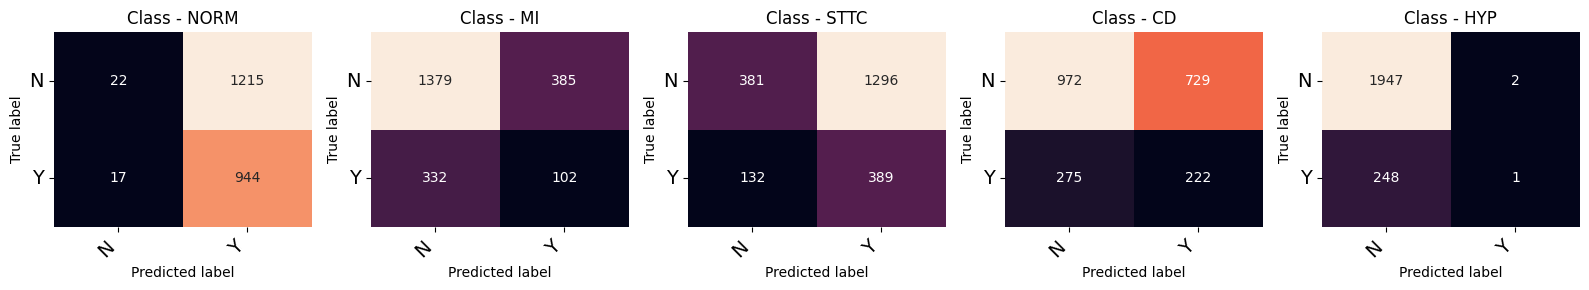

              precision    recall  f1-score   support

        NORM       0.44      0.98      0.61       961
          MI       0.21      0.24      0.22       434
        STTC       0.23      0.75      0.35       521
          CD       0.23      0.45      0.31       497
         HYP       0.33      0.00      0.01       249

   micro avg       0.31      0.62      0.42      2662
   macro avg       0.29      0.48      0.30      2662
weighted avg       0.31      0.62      0.38      2662
 samples avg       0.33      0.64      0.41      2662



In [75]:
from sklearn.metrics import multilabel_confusion_matrix, classification_report

def print_confusion_matrix(confusion_matrix, axes, class_label, class_names, fontsize=14):

    df_cm = pd.DataFrame(confusion_matrix, index=class_names, columns=class_names)

    try:
        heatmap = sns.heatmap(df_cm, annot=True, fmt="d", cbar=False, ax=axes)
    except ValueError:
        raise ValueError("Confusion matrix values must be integers.")
    heatmap.yaxis.set_ticklabels(heatmap.yaxis.get_ticklabels(), rotation=0, ha='right', fontsize=fontsize)
    heatmap.xaxis.set_ticklabels(heatmap.xaxis.get_ticklabels(), rotation=45, ha='right', fontsize=fontsize)
    axes.set_ylabel('True label')
    axes.set_xlabel('Predicted label')
    axes.set_title("Class - " + class_label)



def plot_results(test_preds, test_ground_truth, labels):

    fig, ax = plt.subplots(1, 5, figsize=(16, 3))

    for axes, cfs_matrix, label in zip(ax.flatten(), multilabel_confusion_matrix(test_ground_truth, test_preds), labels):
        print_confusion_matrix(cfs_matrix, axes, label, ["N", "Y"])
        
    fig.tight_layout()
    plt.show()

    print(classification_report(test_ground_truth, test_preds, target_names=labels, zero_division=0))


labels=['NORM', 'MI', 'STTC', 'CD', 'HYP']

test_preds = predict_vae(test_dataloader, device, trained_vae).cpu().numpy()
test_ground_truth = Z_test.to_numpy()

plot_results(test_preds, test_ground_truth, labels)

As you can see, the model performance is average-poor on the test set. All examples were labelled with normal for instance... It is definitely worthy to take a look at different improvements (will be shown on the TODO section). Now, let's take a look at the ones from the VIT (others would be similar)



## Summary
We have tested four approachs, but none of them seemed to be actually working. Honestly, although the goal I had for the exercise was not a deep dive into metrics, it seems the models are underperforming even at a very high level. The reason for this could be a wrong preprocessing on data or a poor choice on the loss function / hyperparameters. Regarding the first one, I have to admit I didn't do more work than the basic scaler one. Regarding the second, some extra experiments would be nice (see more on the TODO part)

The most interesting experiment IMHO is the VAE. Once again, it would encode all info on the latent and could even bring "most similar cases" that could help on a human diagnose. This is definitely the approach I would like to pursue the most.

Regarding the VIT, it is also an interesting option. The training and inference are slower too, but perhaps it is also worthy to take a deeper look at its training and tweak some layers for a better performance.


### Additional learnings / insights

Quoting [Deep Learning for ECG Analysis: Benchmarks and Insights from PTB-XL](https://ieeexplore.ieee.org/document/9190034), uncertainty is not that important ![alternative text](./images/confidence.png). So, we could actually remove the threshold on dataPrep.

According to that paper, the most performing architectures were CNN over LSTM. This is the main reason LSTM has not been tested on this exercise.

Most of the experiments were early stopped. Some were still learning, but most of them were also probe to overfit. Besides extra regularization, some data augmentation (e.g: sliding windows, slight modifications) could do a very good work here.

VIT Seemed to work pretty well with a few epochs. Some questions might arise about how the input is converted to a standard 224 x 224 image and perhaps this is also something worthy to look at.


## TODOS. Things not tried but that should improve the results

I apologize in advance for not trying everything, but I was not able to dedicate as much time as I would have loved to. Among some of the techniques I would have loved to test are the following:
- Different Data Augmentation: adding noise or random time shifts.
- A better DataPrep, trying some more ideas, like including the diagnostic confidence in a better way, if a diagnose has been confirmed, etc. It is quite interesting that we have 1182 with no diagnostic class. Perhaps those ones could be removed for a cleaner training
- Add AUC as metric
- Signal quality
- WhatIf!? Using the 500 data instead?
- Try out different ecg_to_image for the VIT
- Same models with the metadata encoder (what [this person](https://www.kaggle.com/code/jraska1/ptb-xl-ecg-1d-convolution-neural-network#X-and-Y:-1D-CNN-Classifier)) calls X encoder
- Different Normalization: A normalizer instead of a scaler could do greatYou might want to normalize ECG signals based on mean and standard deviation.
- Broader/better hyperparameter fine tunning. TBH, just the basic recipes have been tested, but a deeper, more understandable f-t would have had an impact on the results
- Better residual check


## References
- [this kaggle notebook (Jiří Raška)](https://www.kaggle.com/code/jraska1/ptb-xl-ecg-1d-convolution-neural-network#X-and-Y:-1D-CNN-Classifier): Huge inspiration on adta preparation and model training.
- [Deep Learning for ECG Analysis: Benchmarks and Insights from PTB-XL](https://ieeexplore.ieee.org/document/9190034). A very interesting paper on techiques used and benchmarks for this concrete dataset.
- [Its code](https://github.com/helme/ecg_ptbxl_benchmarking/tree/master), a nice way to replicate their results
- [Extensive EDA on PTB XL](https://www.kaggle.com/code/khyeh0719/ptb-xl-dataset-wrangling), an interesting and inspiring starting point
- [VIT 16](https://pytorch.org/vision/stable/models/generated/torchvision.models.vit_b_16.html), the torch native model